# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr, chi2_contingency


### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:


# mostrar las primeras 5 filas
df.head()




,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**

Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual` (métrica principal)

La mayoría de estas variables presentan tipos de datos adecuados. La columna `edad` está como `float64`, aunque todos sus valores son números enteros (18.0, 36.0…). Se convierte a `int`, que representa mejor una edad en años.

**Variables binarias**

Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**

Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional. `id_cliente` es solo un identificador, por lo que **no se incluye** en ningún cálculo de correlación.

In [4]:
# Corregir el tipo de dato
# edad está como float64, pero todos sus valores son enteros (18.0, 36.0...): se convierte a int
print("Valores de edad con decimales:", (df['edad'] % 1 != 0).sum())
df['edad'] = df['edad'].astype(int)

columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
                      'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']

Valores de edad con decimales: 0


In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
df[columnas_numericas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
edad,15000.0,38.26,11.49,18.0,30.00,38.00,46.00,75.00
nivel_ingreso,15000.0,30019.70,9833.17,8000.0,23127.10,30023.74,36768.44,74790.84
visitas_mes,15000.0,10.03,3.16,1.0,8.00,10.00,12.00,25.00
compras_mes,15000.0,1.21,1.11,0.0,0.00,1.00,2.00,8.00
gasto_publicidad_dirigida,15000.0,20.15,10.88,0.0,12.31,19.73,27.29,75.51
satisfaccion,15000.0,3.60,0.69,1.0,3.10,3.60,4.10,5.00
ingreso_anual,15000.0,36.59,34.48,0.0,0.00,30.70,58.22,244.69


**Diagnóstico inicial de variables numéricas**

- `edad` — Va de 18 a 75 años, con media de 38 y mediana de 38. Distribución simétrica y sin edades poco realistas.
- `nivel_ingreso` — Media ≈ 30,020 y mediana ≈ 30,024 (casi iguales), pero el máximo (74,791) está muy por encima del percentil 75 (36,768): hay pocos clientes con ingresos muy altos. El mínimo es exactamente 8,000, un valor redondo que sugiere un piso o recorte en los datos.
- `visitas_mes` — Entre 1 y 25 visitas, con media de 10. Ningún cliente tiene 0 visitas.
- `compras_mes` — Entre 0 y 8 compras, con media de 1.2. Al menos el 25 % de los clientes no compró nada en el mes (el percentil 25 es 0).
- `gasto_publicidad_dirigida` — Entre 0 y 75.5, con media de 20. El máximo está muy lejos del percentil 75 (27.3), lo que indica algunos valores altos atípicos.
- `satisfaccion` — Escala de 1 a 5 sin valores fuera de rango. Media de 3.6: satisfacción moderada.
- `ingreso_anual` — Media de 36.6 y mediana de 30.7, con un máximo de 244.7. La media mayor que la mediana indica sesgo a la derecha. El percentil 25 es 0: al menos una cuarta parte de los clientes no generó ingreso (la proporción exacta, 30.4 %, se calcula en la Verificación de leakage).

#### Explorar variables binarias

In [7]:
# Verificar que cada columna tenga únicamente dos valores posibles
columnas_binarias = ['miembro_premium', 'abandono']

for col in columnas_binarias:
    print(f"{col}: valores únicos = {sorted(df[col].unique())}")
    resumen = pd.DataFrame({
        'clientes': df[col].value_counts(),
        'proporción': df[col].value_counts(normalize=True).round(3)
    })
    print(resumen)
    print()

miembro_premium: valores únicos = [0, 1]
   clientes  proporción
0     12911       0.861
1      2089       0.139

abandono: valores únicos = [0, 1]
   clientes  proporción
0     12739       0.849
1      2261       0.151



**Diagnóstico inicial de variables binarias**

- `miembro_premium` — Solo toma valores 0 y 1. El 13.9 % de los clientes es premium. Los grupos están desbalanceados: 2,089 premium frente a 12,911 no premium.
- `abandono` — Solo toma valores 0 y 1. El 15.1 % de los clientes abandonó la plataforma (2,261 clientes). También es un grupo minoritario.

#### Explorar variables categóricas

In [8]:
# Verificar el número de valores únicos por variable categórica
columnas_categoricas = ['id_cliente', 'tipo_dispositivo', 'region']
df[columnas_categoricas].nunique()

id_cliente          15000
tipo_dispositivo        3
region                  4
dtype: int64

móvil         0.655
escritorio    0.248
tablet        0.097
Name: proporción, dtype: float64

norte    0.293
oeste    0.254
sur      0.248
este     0.205
Name: proporción, dtype: float64



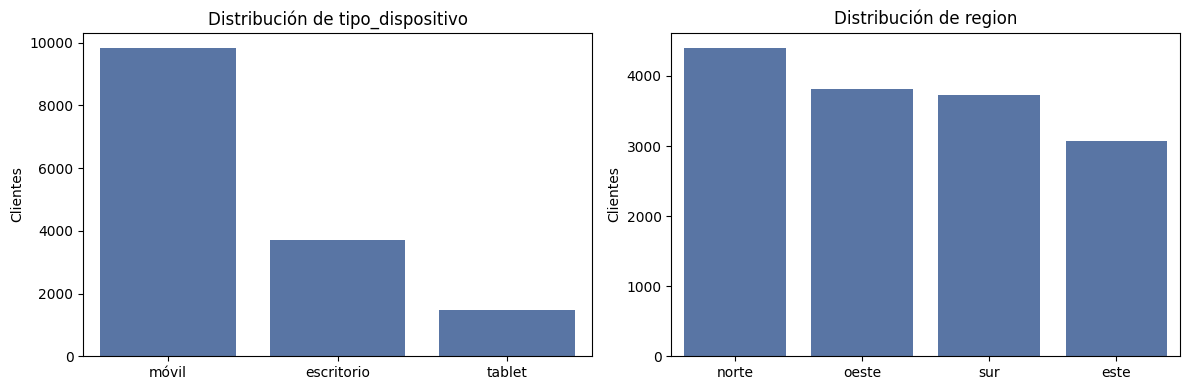

In [9]:
# Explorar variables categóricas y cómo se distribuyen
for col in ['tipo_dispositivo', 'region']:
    print(df[col].value_counts(normalize=True).round(3).rename('proporción'))
    print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['tipo_dispositivo', 'region']):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, color='#4C72B0', ax=ax)
    ax.set_title(f'Distribución de {col}')
    ax.set_xlabel('')
    ax.set_ylabel('Clientes')
plt.tight_layout()
plt.show()

**Diagnóstico inicial de variables categóricas**

- `id_cliente` — 15,000 valores únicos, uno por fila: no hay clientes duplicados. No se usa en el análisis.
- `tipo_dispositivo` — 3 categorías con un desbalance marcado: móvil concentra el 65.5 % de los clientes, escritorio el 24.8 % y tablet solo el 9.7 %.
  - Implicación: los resultados generales están dominados por el comportamiento de los usuarios móviles, y tablet es el grupo con menos clientes, así que sus promedios y correlaciones serán menos estables.
- `region` — 4 categorías con una distribución bastante pareja: norte 29.3 %, oeste 25.4 %, sur 24.8 % y este 20.5 %.

### Supuestos

- Los coeficientes de correlación se calculan con **todo el conjunto de datos** (15,000 clientes). Los scatterplots usan una **muestra aleatoria de 2,000 clientes** (`random_state=42`) solo para que los gráficos sean legibles.
- Los datos no tienen valores nulos ni duplicados, y los tipos se corrigieron donde fue necesario (`edad`). Se asume que los valores están bien registrados, con una salvedad: la definición y el periodo de `ingreso_anual` se cuestionan más adelante (ver Verificación de leakage).
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** mide relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.
- Umbrales usados para interpretar:
  - |r| < 0.1 → sin relación relevante.
  - |r| ≥ 0.5 → relación moderada o fuerte (pares que se grafican en detalle).
  - |r| > 0.85 → posible colinealidad entre variables explicativas.
  - V de Cramér: < 0.1 nula · 0.1–0.3 débil · 0.3–0.5 moderada · > 0.5 fuerte.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

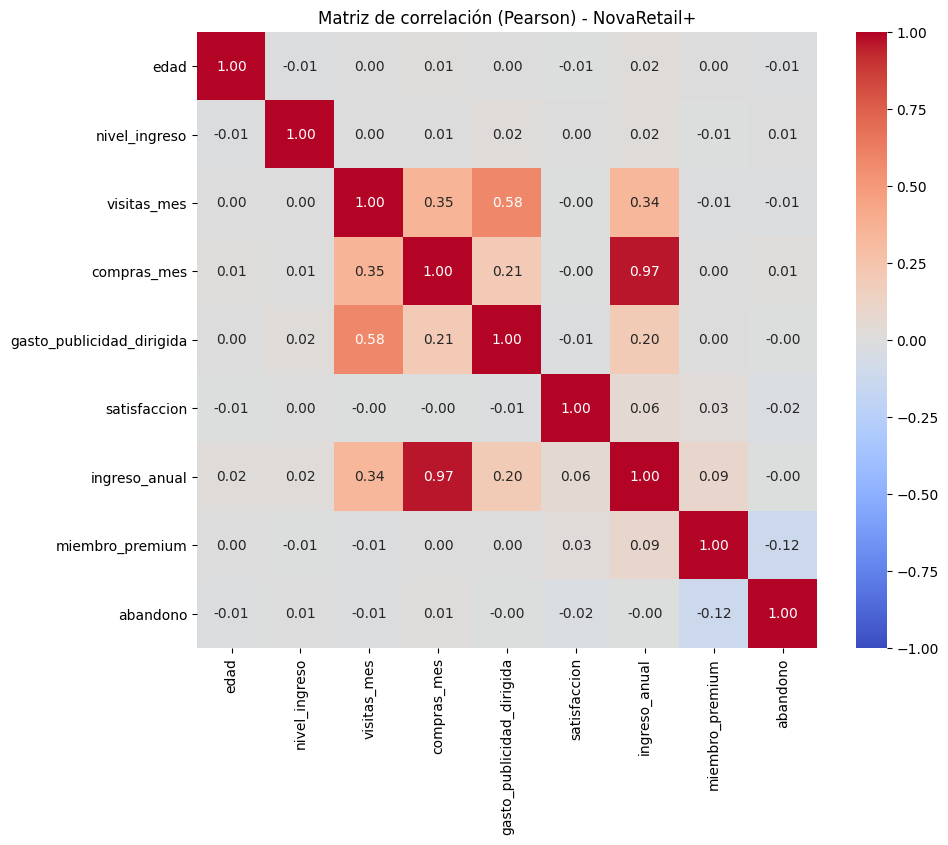

Correlación con ingreso_anual (ordenada por magnitud):
compras_mes                  0.967
visitas_mes                  0.337
gasto_publicidad_dirigida    0.197
miembro_premium              0.093
satisfaccion                 0.056
edad                         0.017
nivel_ingreso                0.017
abandono                    -0.003
Name: ingreso_anual, dtype: float64


In [10]:
# Visualizar la matriz de correlación para identificar relaciones
corr_pearson = df[columnas_numericas + columnas_binarias].corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_pearson, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación (Pearson) - NovaRetail+')
plt.show()

# Ranking de correlación con la métrica principal
print("Correlación con ingreso_anual (ordenada por magnitud):")
print(corr_pearson['ingreso_anual'].drop('ingreso_anual')
      .sort_values(key=abs, ascending=False).round(3))


**Observaciones generales (Heatmap)**

- La mayoría de los pares tienen correlaciones cercanas a 0. `edad`, `nivel_ingreso` y `satisfaccion` casi no se relacionan con ninguna otra variable.
- Entre las variables de comportamiento destaca `visitas_mes` – `gasto_publicidad_dirigida` (r = 0.58, moderada): los clientes que más visitan tienen más gasto publicitario asignado.
- `visitas_mes` – `compras_mes` (r = 0.35) y `compras_mes` – `gasto_publicidad_dirigida` (r = 0.21) muestran relaciones débiles.
- `miembro_premium` – `abandono` (r = -0.12) es una relación negativa débil.

**Observaciones respecto a `ingreso_anual`**

- Presenta una relación inusualmente fuerte con `compras_mes` (r = 0.97). Un valor tan alto entre una variable de comportamiento y la métrica objetivo es sospechoso y merece un análisis más detallado (ver Verificación de leakage).
- Le siguen `visitas_mes` (r = 0.34, débil-moderada) y `gasto_publicidad_dirigida` (r = 0.20, débil).
- `miembro_premium` (0.09), `satisfaccion` (0.06), `edad` (0.02), `nivel_ingreso` (0.02) y `abandono` (≈ 0) prácticamente no se relacionan con `ingreso_anual`.
- Estas son asociaciones, no efectos: el heatmap no indica qué variable influye en cuál.

### Scatterplot general

**Decisión: se incluye un scatterplot general**, usando una muestra aleatoria de 2,000 clientes. Con 15,000 puntos los gráficos se saturan y se vuelven difíciles de leer; una muestra conserva la forma general de las relaciones. El objetivo es revisar la forma de las relaciones (lineal, curva, con grupos o outliers), algo que el heatmap no muestra.

Se excluye `compras_mes`: su relación con `ingreso_anual` es casi determinística (ver Verificación de leakage) y opacaría las demás relaciones.

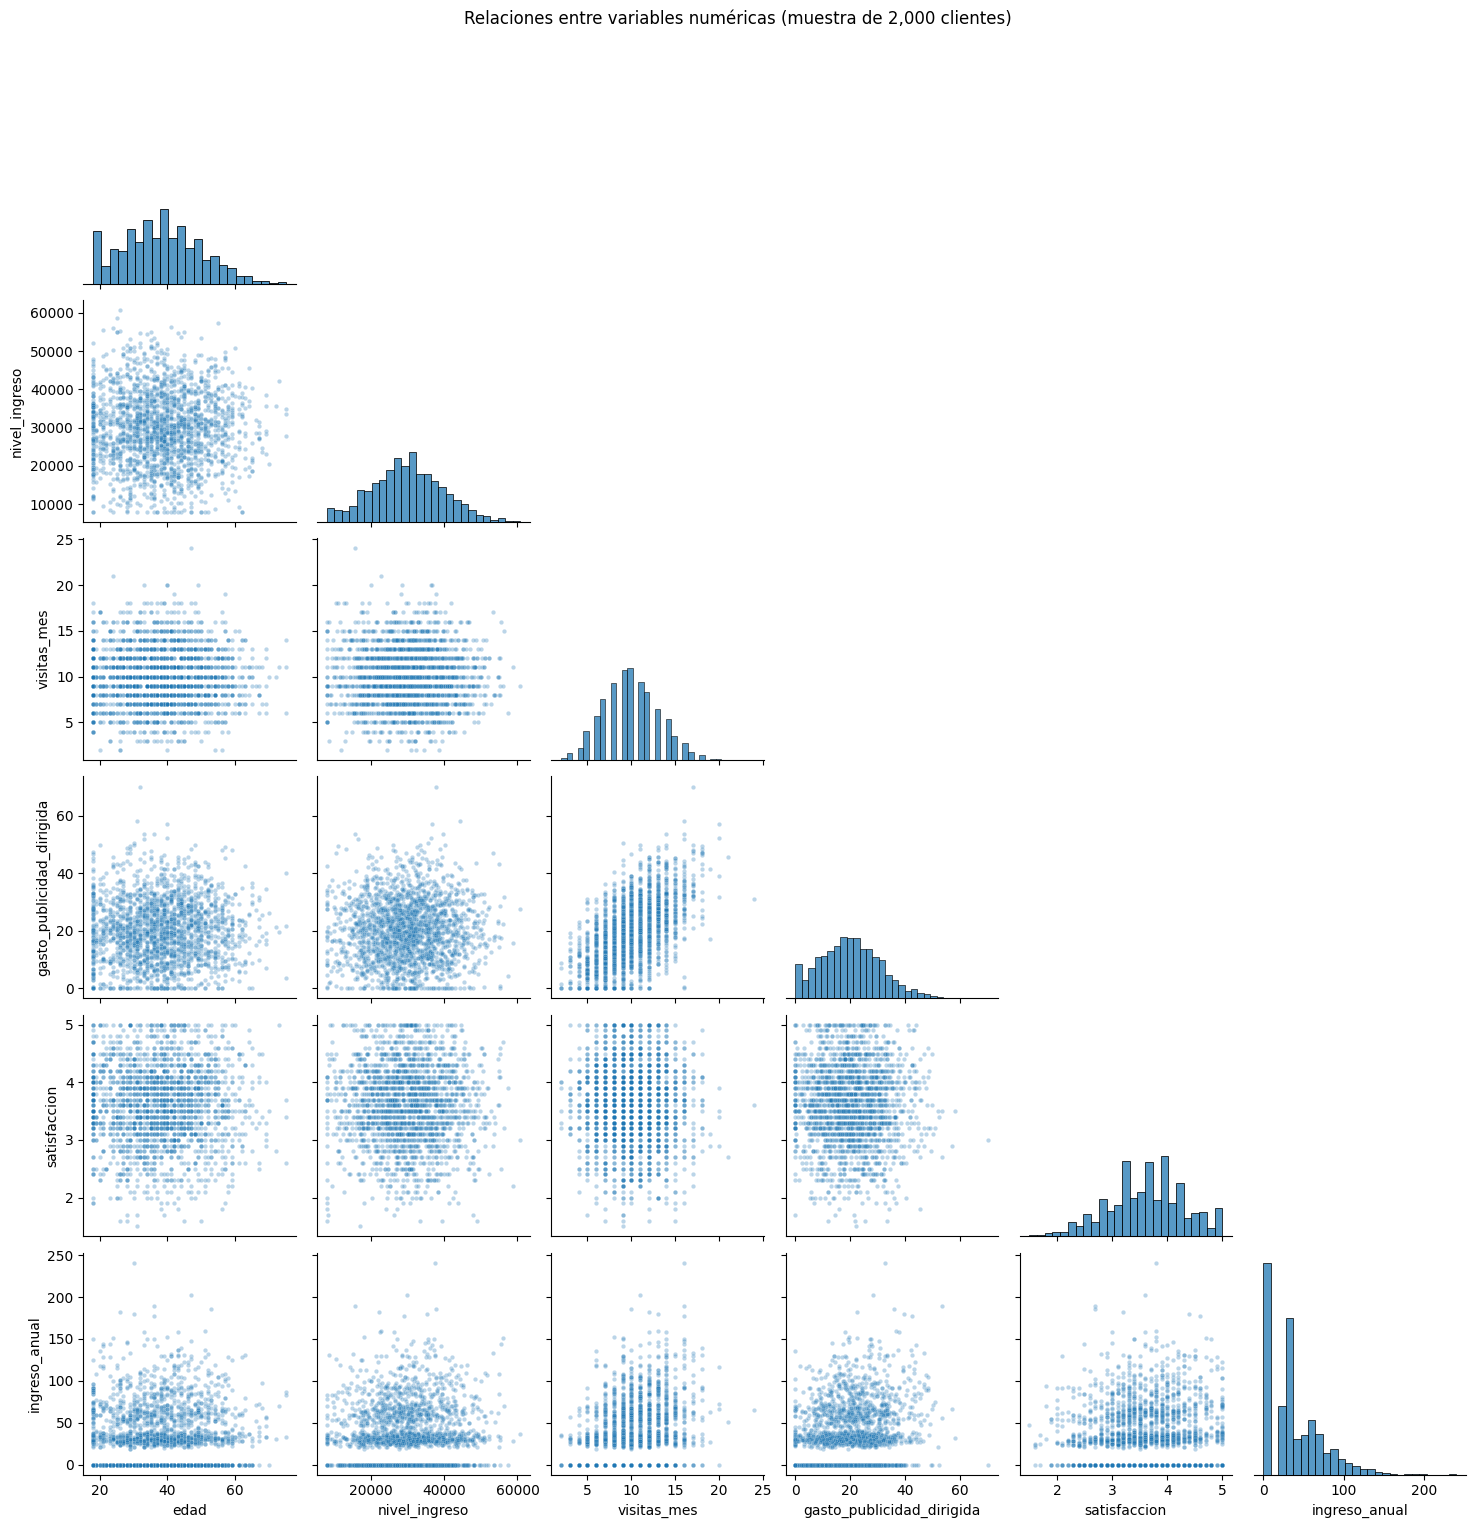

In [11]:
# Scatterplot general (pairplot) sobre una muestra
# Se excluye compras_mes: su relación con ingreso_anual es casi determinística (leakage)
# y ya se muestra en los scatterplots de pares clave
muestra = df.sample(n=2000, random_state=42)
vars_pairplot = [c for c in columnas_numericas if c != 'compras_mes']

sns.pairplot(muestra[vars_pairplot], plot_kws={'alpha': 0.3, 's': 10}, corner=True)
plt.suptitle('Relaciones entre variables numéricas (muestra de 2,000 clientes)', y=1.02)
plt.show()

**Observaciones del scatterplot general (pairplot)**

- **Única relación visible entre explicativas:** `visitas_mes` – `gasto_publicidad_dirigida`. La nube sube de izquierda a derecha en forma de abanico: a más visitas, más gasto asignado y también más variación en ese gasto.
- **Pares sin relación aparente:** los paneles de `edad`, `nivel_ingreso` y `satisfaccion` con el resto son nubes redondas sin dirección, coherentes con sus correlaciones cercanas a 0.
- **`ingreso_anual` tiene una distribución muy sesgada a la derecha**, con un pico grande en 0 (≈ 30 % de los clientes). En todos los paneles de la última fila se ve una **franja horizontal de puntos en 0**, y encima otras franjas en torno a 30 y 60. Esa estructura en escalones sugiere que el ingreso depende de un conteo discreto (las compras), lo que se analiza en la Verificación de leakage.
- **`visitas_mes` vs `ingreso_anual`** muestra columnas (variable discreta) con una tendencia ascendente leve y mucha dispersión.
- **Distribuciones individuales:** `edad` se concentra entre 20 y 50 años, con una cola clara a la derecha hasta los 75; `nivel_ingreso` es casi simétrica alrededor de 30,000, con pocos valores altos; `visitas_mes` es discreta y centrada en 10; `gasto_publicidad_dirigida` tiene un pequeño grupo en 0 (≈ 3 %) y cola a la derecha; `satisfaccion` se concentra entre 3 y 4.5.

### Scatterplot para pares clave

Variables más asociadas con ingreso_anual: ['compras_mes', 'visitas_mes', 'gasto_publicidad_dirigida']


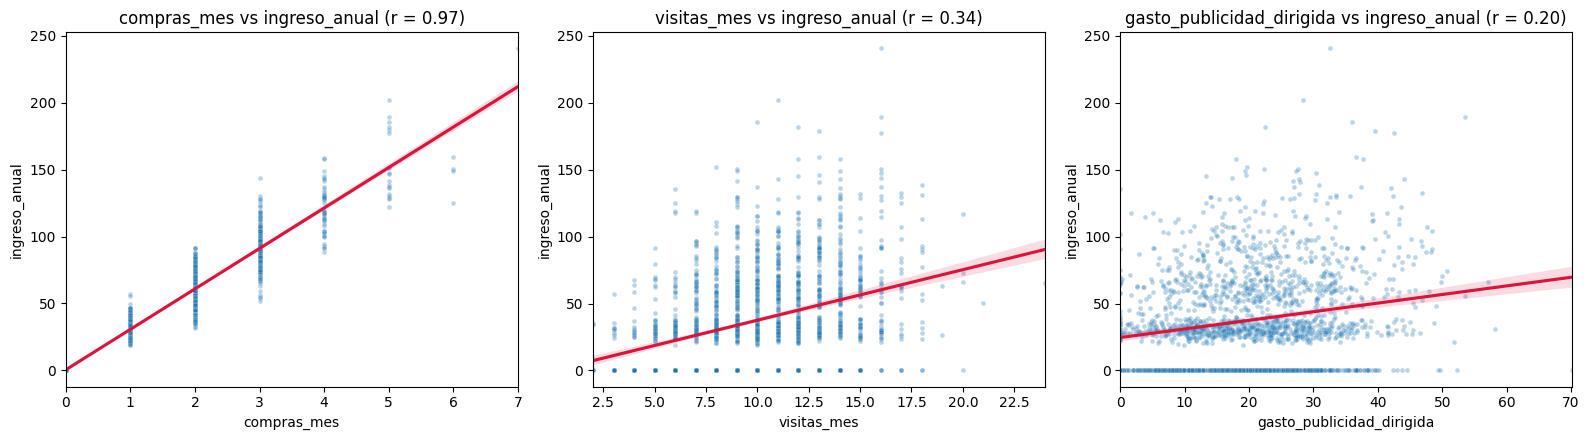

In [12]:
# Visualizar pares de variables con relaciones moderadas o fuertes
# Se eligen automáticamente las 3 variables más correlacionadas con ingreso_anual
top_vars = (corr_pearson['ingreso_anual'].drop('ingreso_anual')
            .abs().sort_values(ascending=False).head(3).index.tolist())
print("Variables más asociadas con ingreso_anual:", top_vars)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, var in zip(axes, top_vars):
    sns.scatterplot(data=muestra, x=var, y='ingreso_anual', alpha=0.3, s=12, ax=ax)
    sns.regplot(data=muestra, x=var, y='ingreso_anual', scatter=False, color='crimson', ax=ax)
    ax.set_title(f'{var} vs ingreso_anual (r = {corr_pearson.loc[var, "ingreso_anual"]:.2f})')
plt.tight_layout()
plt.show()


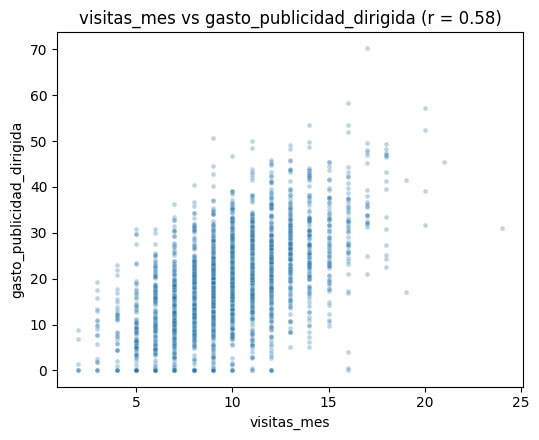

In [13]:
# Pares entre variables explicativas con correlación moderada o fuerte (posible colinealidad)
explicativas = [c for c in columnas_numericas + columnas_binarias if c != 'ingreso_anual']
corr_exp = corr_pearson.loc[explicativas, explicativas]

pares = []
for i, a in enumerate(explicativas):
    for b in explicativas[i + 1:]:
        if abs(corr_exp.loc[a, b]) >= 0.5:
            pares.append((a, b, corr_exp.loc[a, b]))

if pares:
    fig, axes = plt.subplots(1, len(pares), figsize=(5.5 * len(pares), 4.5), squeeze=False)
    for ax, (a, b, r) in zip(axes[0], pares):
        sns.scatterplot(data=muestra, x=a, y=b, alpha=0.3, s=12, ax=ax)
        ax.set_title(f'{a} vs {b} (r = {r:.2f})')
    plt.tight_layout()
    plt.show()
else:
    print("No hay pares de variables explicativas con |r| >= 0.5 (sin señales de colinealidad).")

**Observaciones iniciales (Scatterplot)**

**`compras_mes` vs `ingreso_anual`** (r = 0.97)
- Dirección: positiva.
- Dispersión: baja. Los puntos forman columnas por número de compras (variable discreta), y cada compra adicional se asocia con unos 30 de ingreso adicional.
- Los clientes con 0 compras tienen exactamente 0 de ingreso.
- Relación casi determinística con la variable objetivo (leakage): el ingreso parece construirse a partir de las compras, así que ambas variables miden casi lo mismo. Se comprueba en la sección siguiente.

**`visitas_mes` vs `ingreso_anual`** (r = 0.34)
- Dirección: positiva.
- Dispersión: alta. Con el mismo número de visitas hay clientes con ingreso 0 y otros con ingreso alto.
- Outliers: hay pocos clientes con más de 20 visitas, que se ven alejados del resto.
- Es una relación real pero débil-moderada, muy lejos de la relación casi determinística de `compras_mes`.

**`gasto_publicidad_dirigida` vs `ingreso_anual`** (r = 0.20)
- Dirección: positiva pero débil.
- Dispersión: muy alta; la línea de tendencia tiene una pendiente suave.
- Outliers: hay clientes con gasto alto (> 60) que no se asocian con un ingreso mayor, y un grupo de clientes con gasto 0.

**`visitas_mes` vs `gasto_publicidad_dirigida`** (entre explicativas, r = 0.58)
- Dirección positiva, dispersión media.
- Es el **único par de variables explicativas con |r| ≥ 0.5**. Los siguientes más altos son `visitas_mes` – `compras_mes` (0.35), `compras_mes` – `gasto_publicidad_dirigida` (0.21) y `miembro_premium` – `abandono` (-0.12). El resto está por debajo de |0.05|.
- No llega al umbral de colinealidad (0.85), pero es una asociación moderada: el gasto publicitario tiende a concentrarse en los clientes más activos.
- No podemos saber la dirección de esta relación: puede que se asigne más publicidad a quienes visitan más, o que quienes reciben más publicidad visiten más. También podría haber un tercer factor que influya en ambas.

### Verificación de leakage: `compras_mes` vs `ingreso_anual`

La correlación de 0.97 es sospechosamente alta para dos variables de comportamiento. Verificamos si `ingreso_anual` está construido a partir de `compras_mes` (leakage o fuga de información: una variable explicativa que forma parte del propio resultado).

In [14]:
# 1) ¿Cero compras coincide exactamente con cero ingreso?
print(pd.crosstab(df['compras_mes'] == 0, df['ingreso_anual'] == 0,
                  rownames=['compras = 0'], colnames=['ingreso = 0']))
print()

# 2) Ingreso promedio por número de compras (¿escalones constantes?)
print(df.groupby('compras_mes')['ingreso_anual'].agg(['mean', 'count']).round(1))
print()

# 3) Ingreso por compra: ¿es casi constante?
con_compras = df[df['compras_mes'] > 0]
ingreso_por_compra = con_compras['ingreso_anual'] / con_compras['compras_mes']
print("Ingreso por compra (clientes con al menos una compra):")
print(ingreso_por_compra.describe().round(2))

ingreso = 0  False  True 
compras = 0              
False        10433      0
True             0   4567

              mean  count
compras_mes              
0              0.0   4567
1             30.4   5306
2             60.7   3236
3             90.9   1390
4            121.3    386
5            147.4     91
6            172.6     20
7            206.4      2
8            225.7      2

Ingreso por compra (clientes con al menos una compra):
count    10433.00
mean        30.38
std          5.34
min         11.20
25%         26.78
50%         30.07
75%         33.47
max         57.29
dtype: float64


**Observaciones (leakage)**

- La tabla cruzada muestra que los **4,567 clientes con 0 compras** (30.4 %) son exactamente los mismos que tienen 0 de ingreso: no hay ningún cliente con compras y sin ingreso, ni con ingreso y sin compras.
- El ingreso promedio sube en escalones casi iguales: 30.4 con 1 compra, 60.7 con 2, 90.9 con 3 y 121.3 con 4.
- El ingreso por compra es **bastante estable alrededor de 30, con variación moderada**: media de 30.38, desviación estándar de 5.34 y un rango de ≈ 11 a 57. Esa variación es la razón por la que la correlación es 0.97 y no 1.
- Conclusión: `ingreso_anual` se comporta como compras × un monto por compra bastante constante (≈ 30). `compras_mes` es un componente del propio ingreso y no un factor de comportamiento, así que se excluye de los hallazgos de comportamiento y del análisis por segmentos.
- Hipótesis por confirmar con el equipo de datos: si el ingreso fuera anual a partir de compras mensuales, se esperaría un valor cercano a 12 × 30 por compra. La escala sugiere que la métrica podría ser mensual, pero estos resultados no lo prueban (ver Limitaciones).

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [15]:
# Calcular correlación entre variables relevantes
# Pearson vs Spearman de cada variable con ingreso_anual
comparacion = pd.DataFrame({
    'pearson': df[columnas_numericas].corr(method='pearson')['ingreso_anual'],
    'spearman': df[columnas_numericas].corr(method='spearman')['ingreso_anual'],
}).drop('ingreso_anual')
comparacion['diferencia'] = comparacion['spearman'] - comparacion['pearson']
comparacion.sort_values('spearman', key=abs, ascending=False).round(3)


,pearson,spearman,diferencia
compras_mes,0.967,0.967,0.000
visitas_mes,0.337,0.321,-0.016
gasto_publicidad_dirigida,0.197,0.185,-0.012
satisfaccion,0.056,0.061,0.005
nivel_ingreso,0.017,0.025,0.008
edad,0.017,0.016,-0.001


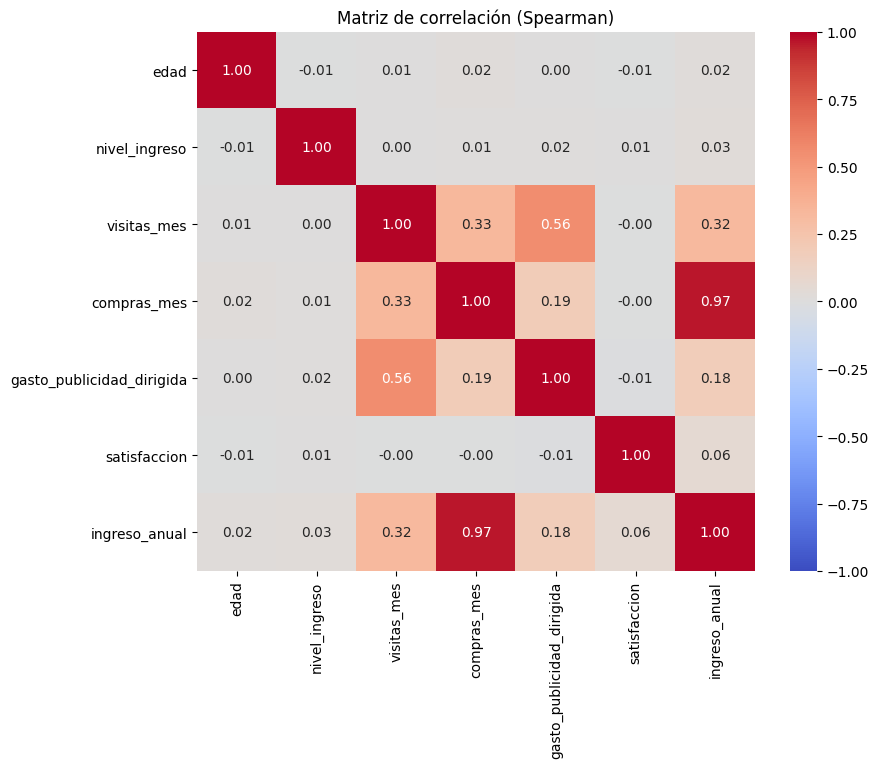

Pares de explicativas con posible colinealidad (|r| > 0.85): ninguno


In [16]:
# Calcular correlación entre variables relevantes
# Matriz Spearman completa (incluye ingreso_anual para ver su relación con cada variable)
corr_spearman = df[columnas_numericas].corr(method='spearman')

plt.figure(figsize=(9, 7))
sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación (Spearman)')
plt.show()

# Colinealidad: solo entre variables explicativas (se excluye la variable objetivo)
explicativas_num = [c for c in columnas_numericas if c != 'ingreso_anual']
colineales = [(a, b, round(corr_spearman.loc[a, b], 3))
              for i, a in enumerate(explicativas_num)
              for b in explicativas_num[i + 1:]
              if abs(corr_spearman.loc[a, b]) > 0.85]
print("Pares de explicativas con posible colinealidad (|r| > 0.85):", colineales if colineales else "ninguno")


**Observaciones de correlación**

**`compras_mes` vs `ingreso_anual`**
- Pearson = 0.967 y Spearman = 0.967 → relación positiva muy fuerte.
- No es colinealidad entre explicativas, sino una relación casi determinística con la variable objetivo (leakage), como se comprobó en la Verificación de leakage. Por eso este par no se interpreta como un hallazgo de comportamiento.

**`visitas_mes` vs `ingreso_anual`**
- Pearson = 0.337 y Spearman = 0.321 → relación positiva débil-moderada. Los dos métodos coinciden, lo que indica una relación consistente. La forma de la relación se observa en el scatterplot: tendencia ascendente leve con mucha dispersión.

**`gasto_publicidad_dirigida` vs `ingreso_anual`**
- Pearson = 0.197 y Spearman = 0.185 → relación positiva débil; ambos métodos coinciden. En el scatterplot la pendiente es suave y la dispersión muy alta.

**Variables sin relación relevante**
- `satisfaccion` (0.06), `nivel_ingreso` (0.02–0.03) y `edad` (0.02): |r| < 0.1 con ambos métodos.

**Colinealidad entre variables explicativas**
- La búsqueda se hizo excluyendo `ingreso_anual`: ningún par de explicativas supera 0.85. El más alto es `visitas_mes` – `gasto_publicidad_dirigida`: Spearman = 0.56 (heatmap de Spearman de esta sección) y Pearson = 0.58 (heatmap de Pearson de la Sección 3). Es una asociación moderada.

### Punto-biserial

In [17]:
# Calcular correlación entre variables relevantes
# Punto-biserial: variables binarias vs variables numéricas
resultados_pb = []
for col_bin in columnas_binarias:
    for col_num in columnas_numericas:
        coef, p_value = pointbiserialr(df[col_bin], df[col_num])
        resultados_pb.append({'binaria': col_bin, 'numérica': col_num,
                              'r_pb': round(coef, 3), 'p_value': round(p_value, 4)})

tabla_pb = pd.DataFrame(resultados_pb)
display(tabla_pb)

# Complemento descriptivo: ingreso_anual promedio por grupo
for col_bin in columnas_binarias:
    print(df.groupby(col_bin)['ingreso_anual'].agg(['mean', 'median', 'count']).round(2))
    print()

,binaria,numérica,r_pb,p_value
0,miembro_premium,edad,0.005,0.5728
1,miembro_premium,nivel_ingreso,-0.006,0.4930
2,miembro_premium,visitas_mes,-0.013,0.1211
3,miembro_premium,compras_mes,0.003,0.6744
4,miembro_premium,gasto_publicidad_dirigida,0.003,0.7390
5,miembro_premium,satisfaccion,0.026,0.0016
6,miembro_premium,ingreso_anual,0.093,0.0000
7,abandono,edad,-0.012,0.1590
8,abandono,nivel_ingreso,0.006,0.4722
9,abandono,visitas_mes,-0.009,0.2734


                  mean  median  count
miembro_premium                      
0                35.30   29.95  12911
1                44.58   37.70   2089

           mean  median  count
abandono                      
0         36.64   30.69  12739
1         36.36   30.72   2261



**Observaciones Punto-biserial**

**miembro_premium vs ingreso_anual**

- Relación positiva de magnitud baja (r_pb = 0.093, p < 0.001).
- Ingreso anual promedio: 44.58 en premium frente a 35.30 en no premium (≈ 26 % más). La diferencia es clara en promedio, aunque la correlación es baja porque dentro de cada grupo hay mucha variación.

**abandono vs ingreso_anual**

- Relación prácticamente nula (r_pb = -0.003, p = 0.73).
- Ingreso anual promedio casi idéntico: 36.36 entre quienes abandonaron frente a 36.64 entre quienes no.

**Otras relaciones**

- satisfaccion muestra relaciones muy bajas con miembro_premium (0.026) y con abandono (-0.024). Son estadísticamente significativas por el tamaño de la muestra, pero su magnitud no tiene relevancia práctica.
- abandono no se relaciona con visitas, compras ni gasto publicitario (|r_pb| < 0.02).

### V de Cramér

In [18]:
# Función para calcular V de Cramér
def cramers_v(df, col_1, col_2):
    tabla = pd.crosstab(df[col_1], df[col_2])
    chi2, _, _, _ = chi2_contingency(tabla)
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))


,variable_1,variable_2,V_cramer
5,miembro_premium,abandono,0.120
1,tipo_dispositivo,miembro_premium,0.020
4,region,abandono,0.015
3,region,miembro_premium,0.013
0,tipo_dispositivo,region,0.012
2,tipo_dispositivo,abandono,0.007


Tasa de abandono por estatus premium:
                 tasa_abandono  clientes_abandono  clientes_total
miembro_premium                                                  
0                        0.168               2170           12911
1                        0.044                 91            2089

                   mean  median  count
tipo_dispositivo                      
escritorio        36.42   30.44   3720
móvil             36.59   30.69   9818
tablet            37.07   31.34   1462

         mean  median  count
region                      
este    36.89   30.78   3069
norte   36.71   30.72   4395
oeste   35.72   30.36   3810
sur     37.10   30.94   3726



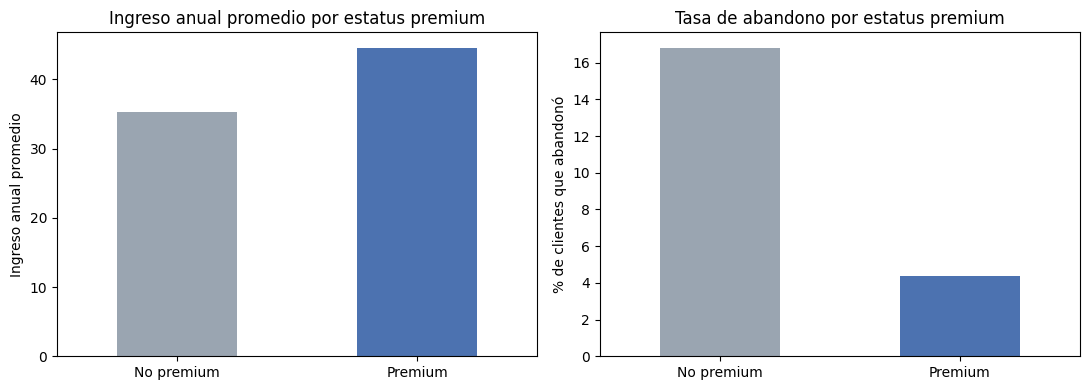

In [19]:
# Aplicar V de Cramér en variables relevantes
variables_cat = ['tipo_dispositivo', 'region', 'miembro_premium', 'abandono']

resultados_v = []
for i, a in enumerate(variables_cat):
    for b in variables_cat[i + 1:]:
        resultados_v.append({'variable_1': a, 'variable_2': b, 'V_cramer': round(cramers_v(df, a, b), 3)})

display(pd.DataFrame(resultados_v).sort_values('V_cramer', ascending=False))

# Tasa de abandono según estatus premium
tasa_abandono = df.groupby('miembro_premium')['abandono'].agg(['mean', 'sum', 'count'])
tasa_abandono.columns = ['tasa_abandono', 'clientes_abandono', 'clientes_total']
print("Tasa de abandono por estatus premium:")
print(tasa_abandono.round(3))
print()

# Complemento descriptivo: ingreso_anual por segmento categórico
for col in ['tipo_dispositivo', 'region']:
    print(df.groupby(col)['ingreso_anual'].agg(['mean', 'median', 'count']).round(2))
    print()

# Evidencia visual premium: ingreso promedio y tasa de abandono por grupo
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
etiquetas = {0: 'No premium', 1: 'Premium'}

ingreso_premium = df.groupby('miembro_premium')['ingreso_anual'].mean().rename(index=etiquetas)
ingreso_premium.plot(kind='bar', ax=axes[0], color=['#9AA5B1', '#4C72B0'], rot=0)
axes[0].set_title('Ingreso anual promedio por estatus premium')
axes[0].set_xlabel('')
axes[0].set_ylabel('Ingreso anual promedio')

(tasa_abandono['tasa_abandono'] * 100).rename(index=etiquetas).plot(
    kind='bar', ax=axes[1], color=['#9AA5B1', '#4C72B0'], rot=0)
axes[1].set_title('Tasa de abandono por estatus premium')
axes[1].set_xlabel('')
axes[1].set_ylabel('% de clientes que abandonó')

plt.tight_layout()
plt.show()

**Observaciones V de Cramér**

- La asociación más alta se da entre `miembro_premium` y `abandono` (V = 0.12, débil). La tabla de tasas muestra un abandono del 4.4 % en clientes premium (91 de 2,089) frente al 16.8 % en no premium (2,170 de 12,911).
- Los demás pares tienen V ≤ 0.02 (nula): el tipo de dispositivo y la región no se asocian entre sí, ni con ser premium, ni con abandonar.
- Ingreso anual por segmento: los promedios por dispositivo (36.4–37.1) y por región (35.7–37.1) son muy parecidos. Ni la región ni el dispositivo marcan diferencias relevantes en el ingreso.
- Los gráficos de barras muestran las dos diferencias del grupo premium: más ingreso promedio y una tasa de abandono mucho menor.

Referencia: V < 0.1 nula · 0.1–0.3 débil · 0.3–0.5 moderada · > 0.5 fuerte.

### Verificación por segmentos (posibles correlaciones engañosas)

Una correlación general puede cambiar, desaparecer o invertirse al separar por grupos (paradoja de Simpson). Revisamos dos cosas:
1. Si la relación de las variables más asociadas con `ingreso_anual` se mantiene dentro de cada segmento (premium, dispositivo y región). Se excluye `compras_mes` por el leakage detectado.
2. Si la relación entre `gasto_publicidad_dirigida` e `ingreso_anual` se mantiene al comparar clientes con un nivel de visitas parecido, ya que ambas variables están asociadas con `visitas_mes` (r = 0.58).

In [20]:
# Correlación (Spearman) de las variables top con ingreso_anual dentro de cada segmento
# Se excluye compras_mes por leakage (ver Verificación de leakage)
vars_segmento = [v for v in top_vars if v != 'compras_mes']

for seg in ['miembro_premium', 'tipo_dispositivo', 'region']:
    tabla_seg = (df.groupby(seg)
                   .apply(lambda g: g[vars_segmento].corrwith(g['ingreso_anual'], method='spearman'))
                   .round(3))
    print(f"Por {seg}:")
    display(tabla_seg)

# ¿La relación gasto publicitario - ingreso se mantiene entre clientes con un nivel de visitas parecido?
df['grupo_visitas'] = pd.qcut(df['visitas_mes'], 4)
print("Correlación gasto_publicidad_dirigida vs ingreso_anual dentro de cada cuartil de visitas:")
display(df.groupby('grupo_visitas', observed=True)
          .apply(lambda g: g['gasto_publicidad_dirigida'].corr(g['ingreso_anual']))
          .round(3).rename('pearson'))
df = df.drop(columns='grupo_visitas')

Por miembro_premium:


,visitas_mes,gasto_publicidad_dirigida
miembro_premium,,
0,0.327,0.189
1,0.295,0.164


Por tipo_dispositivo:


,visitas_mes,gasto_publicidad_dirigida
tipo_dispositivo,,
escritorio,0.312,0.182
móvil,0.325,0.189
tablet,0.314,0.165


Por region:


,visitas_mes,gasto_publicidad_dirigida
region,,
este,0.331,0.192
norte,0.324,0.173
oeste,0.297,0.181
sur,0.334,0.198


Correlación gasto_publicidad_dirigida vs ingreso_anual dentro de cada cuartil de visitas:


grupo_visitas
(0.999, 8.0]    0.066
(8.0, 10.0]     0.004
(10.0, 12.0]    0.016
(12.0, 25.0]    0.045
Name: pearson, dtype: float64

**Observaciones por segmento**

- Las correlaciones de `visitas_mes` (≈ 0.30–0.33) y `gasto_publicidad_dirigida` (≈ 0.16–0.20) con `ingreso_anual` son muy similares en todos los segmentos de premium, dispositivo y región. No se observa paradoja de Simpson en estos cortes.
- Esto incluye a tablet, el dispositivo con menos clientes (9.7 %): sus correlaciones son parecidas a las de móvil y escritorio.
- **Correlación engañosa detectada:** al comparar clientes con un nivel de visitas parecido (cuartiles de `visitas_mes`), la correlación entre `gasto_publicidad_dirigida` e `ingreso_anual` cae a valores entre 0.004 y 0.066. En esta comprobación se usa Pearson para compararla directamente con la correlación general de Pearson (0.20) del heatmap. La relación general (0.20) parece explicarse en gran parte porque el gasto publicitario se asigna más a los clientes que más visitan, no porque la publicidad se asocie por sí sola con más ingreso.

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — La actividad en la plataforma (visitas) es el factor de comportamiento más asociado con el ingreso

**Evidencia visual:** El scatterplot de `visitas_mes` vs `ingreso_anual` muestra una tendencia ascendente con dispersión alta.

**Evidencia numérica:** Pearson = 0.34 y Spearman = 0.32. La relación se mantiene en todos los segmentos (0.30–0.33 por premium, dispositivo y región).

Nota: `compras_mes` tiene una correlación mucho mayor (0.97), pero es un caso de leakage (ver la sección Verificación de leakage, en la Sección 3): los clientes con 0 compras tienen 0 de ingreso, y cada compra se asocia con unos 30 de ingreso. Es un componente del ingreso más que un factor que lo explique, por eso no se presenta como hallazgo.

**Interpretación**

Los clientes que visitan más la plataforma **tienden a** generar más ingreso anual. La relación es débil-moderada: muchos clientes con muchas visitas generan poco ingreso.

**No podemos afirmar**

Que aumentar las visitas aumente el ingreso. La relación podría ir en sentido contrario (los clientes que compran más vuelven más a la plataforma) o depender de una tercera variable no medida, como la necesidad de compra o la antigüedad del cliente.

**Implicación de negocio**

`visitas_mes` puede usarse como **señal temprana** para identificar clientes con potencial de valor. Para saber si impulsar las visitas (notificaciones, recordatorios) genera más ingreso, habría que validarlo con un experimento A/B.

### Hallazgo 2 — La relación entre gasto publicitario e ingreso es débil y parece explicarse por las visitas

**Evidencia visual:** El scatterplot de `gasto_publicidad_dirigida` vs `ingreso_anual` muestra una pendiente suave con dispersión muy alta.

**Evidencia numérica:** Pearson = 0.20 y Spearman = 0.19 en el total. El gasto se asocia con las visitas (r = 0.58), y dentro de grupos de clientes con visitas parecidas la correlación con el ingreso cae a 0.00–0.07.

**Interpretación**

El gasto publicitario se concentra en los clientes más activos. Una vez que se compara a clientes con un nivel de actividad similar, el gasto publicitario casi no se asocia con el ingreso.

**No podemos afirmar**

Que la publicidad dirigida genere ingreso, ni tampoco que no funcione. Estos datos muestran cómo se **reparte** el presupuesto, no su efecto. Medir el efecto real requiere un diseño experimental.

**Implicación de negocio**

No conviene usar esta correlación para justificar aumentar ni recortar el presupuesto publicitario. Se recomienda una prueba A/B con un grupo de control sin publicidad dirigida, comparando clientes con niveles de actividad similares.

### Hallazgo 3 — Ser premium se asocia con más ingreso y con menos abandono, aunque de forma débil

**Evidencia visual:** Gráficos de barras de ingreso anual promedio y tasa de abandono por estatus premium (sección V de Cramér).

**Evidencia numérica:** Punto-biserial con `ingreso_anual` = 0.093. Ingreso promedio de 44.58 en premium frente a 35.30 en no premium. V de Cramér premium–abandono = 0.12: tasa de abandono del 4.4 % en premium frente al 16.8 % en no premium (tabla de tasas de la sección V de Cramér).

**Interpretación**

Los clientes premium **tienden a** generar algo más de ingreso y a abandonar menos la plataforma. Las asociaciones son débiles: hay mucha variación dentro de cada grupo.

**No podemos afirmar**

Que la suscripción premium cause más ingreso o más retención. Es probable que los clientes más comprometidos con la plataforma sean justamente los que eligen hacerse premium (autoselección).

**Implicación de negocio**

El programa premium merece un análisis más profundo, por ejemplo comparando a los mismos clientes antes y después de suscribirse, o probando ofertas premium con un experimento controlado antes de invertir en promoverlo masivamente.

### Hallazgo 4 (complementario) — Edad, nivel de ingreso, satisfacción, abandono, región y dispositivo no se asocian con el ingreso generado

**Evidencia visual:** En el pairplot, los paneles de `edad`, `nivel_ingreso` y `satisfaccion` frente a `ingreso_anual` son nubes sin dirección. En el heatmap, sus celdas en la fila de `ingreso_anual` están cerca de 0.

**Evidencia numérica:** |r| < 0.1 para `edad` (0.02), `nivel_ingreso` (0.02) y `satisfaccion` (0.06). `abandono` tampoco se relaciona con el ingreso (r_pb ≈ 0; ingreso promedio de 36.36 frente a 36.64). El ingreso promedio por región (35.7–37.1) y por dispositivo (36.4–37.1) es casi igual.

**Interpretación**

En este dataset, estas variables no distinguen a los clientes de mayor y menor ingreso. Llama la atención que los clientes que abandonaron generen el mismo ingreso que los que se quedan.

**No podemos afirmar**

Que estas variables no importen para el negocio. Una correlación cercana a 0 solo descarta una relación lineal o monótona general: podría haber relaciones de otra forma o dentro de subgrupos que estos coeficientes no detectan. La satisfacción, por ejemplo, puede ser clave para otros objetivos como la experiencia de usuario.

**Implicación de negocio**

No conviene priorizar la segmentación por edad, nivel de ingreso, abandono, región o dispositivo para identificar clientes de alto valor. Que el abandono no se asocie con el ingreso sugiere que los clientes que se van no son necesariamente los de menor valor, un punto que vale la pena revisar con el equipo de retención.

### Hallazgo 5 — La correlación más alta del dataset (compras vs. ingreso) es un artefacto de cómo se construye la métrica

**Evidencia visual:** El scatterplot de `compras_mes` vs `ingreso_anual` muestra columnas casi alineadas en una recta, con escalones de ~30 por compra.

**Evidencia numérica** (ver Verificación de leakage, Sección 3): Pearson = Spearman = 0.967. La tabla cruzada muestra que los 4,567 clientes con 0 compras son exactamente los mismos que tienen 0 de ingreso. El ingreso por compra es casi constante (media de 30.38, desviación estándar de 5.34).

**Interpretación**

`ingreso_anual` parece calcularse como compras × ticket promedio. La correlación de 0.97 no describe un comportamiento del cliente: refleja que una variable es componente de la otra (leakage).

**No podemos afirmar**

Que las compras "expliquen" el ingreso como un factor independiente, ni que la métrica sea realmente anual: su escala (media de 36.6) es más compatible con un valor mensual.

**Implicación de negocio**

Antes de usar `ingreso_anual` en reportes o decisiones, conviene confirmar con el equipo de datos su definición y periodo. En análisis futuros, separar "si el cliente compra" de "cuánto gasta por compra" daría una lectura más útil del valor del cliente.

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**

**Sobre la interpretación**
- Correlación ≠ causalidad: ningún hallazgo demuestra que una variable produzca cambios en el ingreso anual.
- Pearson, Spearman y punto-biserial solo detectan relaciones lineales o monótonas; otras formas de relación pueden pasar desapercibidas.

**Sobre la métrica principal**
- `compras_mes` presenta leakage (fuga de información) con `ingreso_anual`: es casi un componente del propio ingreso (r = 0.97; 0 compras = 0 ingreso), por lo que no sirve para explicarlo.
- La escala de `ingreso_anual` (media de 36.6 y unos 30 por compra mensual) se parece más a un valor mensual que anual. Habría que confirmar con el equipo de datos cómo se calcula esta métrica.

**Sobre cómo se generaron los datos**
- El gasto publicitario no se asigna al azar: parece concentrarse en los clientes más activos, lo que impide medir su efecto con datos observacionales.
- Posible autoselección en `miembro_premium`: los clientes más comprometidos podrían ser los que eligen suscribirse.
- Posibles variables omitidas (antigüedad del cliente, categoría de productos, promociones recibidas) que podrían explicar las asociaciones observadas.

**Sobre el alcance de los datos**
- Datos de un solo periodo (2024): no permiten ver si las relaciones cambian en el tiempo.
- Los grupos premium (13.9 %), abandono (15.1 %) y tablet (9.7 %) son minoritarios, lo que hace menos estables las comparaciones.

### **Próximos pasos**

**Probar segmentación adicional**
- Analizar las relaciones por rangos de edad y de `nivel_ingreso`, y combinando segmentos (por ejemplo, premium × región).
- Analizar solo a los clientes con al menos una compra, para separar "si compra" de "cuánto gasta por compra".

**Validar relaciones con experimentos**
- Prueba A/B de publicidad dirigida con un grupo de control, comparando clientes con niveles de actividad similares.
- Prueba controlada de ofertas premium para medir su efecto en el ingreso y en la retención.

**Mejorar los datos**
- Confirmar la definición y el periodo de `ingreso_anual`.
- Incorporar datos de varios periodos y variables como la antigüedad del cliente o la categoría de compra.